# Figure 6 — blank-corrected treatment-associated metabolomics and recurrence-linked inferred activity

Every individual main and supplementary panel below explicitly loads its checksummed, plot-ready data, displays a compact input audit, and renders the figure in real time. The compiled figures are rebuilt from the same in-memory DataFrames.

## Plot-only execution contract

This notebook renders existing intermediate numerical results only. It does not recompute upstream analysis.


In [1]:
PLOT_ONLY_FIGURE = "Figure_6"
ANALYSIS_RECOMPUTED = False
ALLOWED_INPUT_SUFFIXES = {".h5ad", ".h5", ".csv", ".gz", ".parquet", ".json"}
print(PLOT_ONLY_FIGURE, "plot-only mode; analysis_recomputed=", ANALYSIS_RECOMPUTED)


Figure_6 plot-only mode; analysis_recomputed= False


In [2]:
# Local, checksummed Figure 6 data only; no upstream analysis paths are accessed.
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
from IPython.display import display
import hashlib, json
import pandas as pd
ROOT = Path.cwd()
DATA_ROOT = ROOT / 'data'
DATA_MANIFEST = json.loads((DATA_ROOT / 'manifest.json').read_text())
if DATA_MANIFEST.get('format_version') != 2 or set(DATA_MANIFEST.get('panels', {})) != set('ABCDEF'):
    raise RuntimeError('Figure 6 data manifest is not the authoritative A–F revision')
if set(DATA_MANIFEST.get('supplementary_panels', {})) != {'SA', 'SB', 'SC', 'SD', 'SE', 'SF', 'SG', 'SH', 'SI'}:
    raise RuntimeError('Figure 6 data manifest is missing supplementary SA–SI lineage')
_EXPECTED_HASHES = {row['name']: row['sha256'] for row in DATA_MANIFEST['files']}
def _verify_staged_file(filename):
    path = DATA_ROOT / filename
    observed = hashlib.sha256(path.read_bytes()).hexdigest()
    if observed != _EXPECTED_HASHES.get(filename):
        raise RuntimeError(f'Checksum mismatch for {filename}')
def _audit_panel_data(label, tables, panel_group=None):
    panel_group = panel_group or ('panels' if label in DATA_MANIFEST['panels'] else 'supplementary_panels')
    declared = {row['path'] for row in DATA_MANIFEST[panel_group][label]['inputs']}
    if set(tables) != declared:
        raise RuntimeError(f'Panel {label} inputs do not match manifest: {set(tables)} != {declared}')
    audit = pd.DataFrame([
        {'panel': label, 'file': name, 'rows': len(table), 'columns': len(table.columns)}
        for name, table in tables.items()
    ])
    display(audit)
    for name, table in tables.items():
        print(f'{name}: first three rows')
        display(table.head(3))
PANEL_DATA, SUPPLEMENTARY_DATA = {}, {}
print('Validated checksummed blank-corrected Figure 6 A–F and SA–SI data package.')

Validated checksummed blank-corrected Figure 6 A–F and SA–SI data package.


## Visible plotting helpers

These are the complete Matplotlib/Seaborn functions used below. They accept already-loaded DataFrames or the checksummed immutable Panel B image and contain no hidden file reads or imports from an external plotting module.

In [3]:
import plotting as plot
plot.DATA_MANIFEST=DATA_MANIFEST
plot.DATA_ROOT=DATA_ROOT
plot._verify_staged_file=_verify_staged_file
plot._audit_panel_data=_audit_panel_data
plot.PANEL_DATA=PANEL_DATA
plot.SUPPLEMENTARY_DATA=SUPPLEMENTARY_DATA
from plotting import *

## Supplementary Figure 6A — live plot from staged data

The cell names every input file, verifies its checksum, previews the data, and renders this panel.

,panel,file,rows,columns
0,SA,status_four_set_membership.csv,34,3


status_four_set_membership.csv: first three rows


,candidate_pathway,mapped_to_humangem,human_gem_pathway
0,Aminosugars metabolism,True,Amino_sugar_and_nucleotide_sugar_metabolism
1,Ascorbate (Vitamin C) and Aldarate Metabolism,True,Ascorbate_and_aldarate_metabolism
2,Aspartate and asparagine metabolism,True,Alanine_aspartate_and_glutamate_metabolism


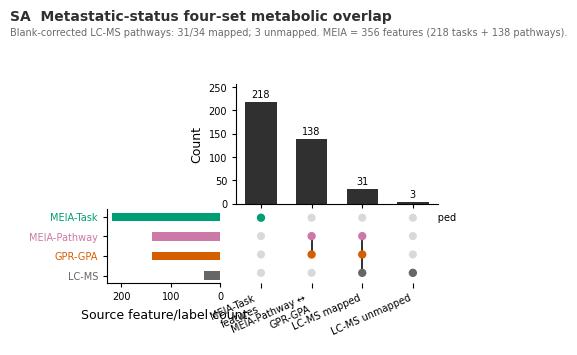

In [4]:
_render_extension_panel('SA','status_four_set_membership.csv',SUPPLEMENTARY_DATA,'supplementary_panels')

## Supplementary Figure 6B — live plot from staged data

The cell names every input file, verifies its checksum, previews the data, and renders this panel.

,panel,file,rows,columns
0,SB,status_pathway_scatter.csv,34,7


status_pathway_scatter.csv: first three rows


,rank,pathway,enrichment_factor,neg_log10_p,radius,label_top5,coordinate_source
0,1,Hexose phosphorylation,2.600104,1.310194,1.612484,True,PRIVATE_ARCHIVE_ROOT/metabolomics_all_analaysi...
1,2,Pentose phosphate pathway,2.080011,0.994862,1.442224,True,PRIVATE_ARCHIVE_ROOT/metabolomics_all_analaysi...
2,3,Glycolysis and Gluconeogenesis,2.311123,0.806263,1.520238,True,PRIVATE_ARCHIVE_ROOT/metabolomics_all_analaysi...


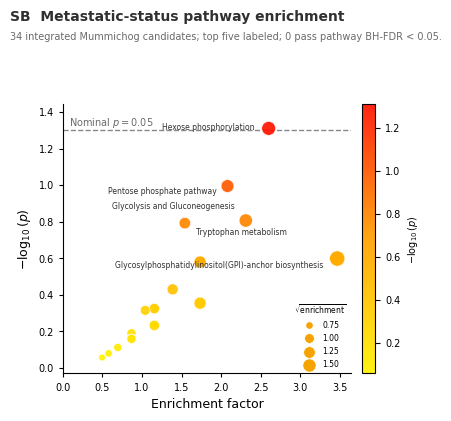

In [5]:
_verify_staged_file('status_pathway_scatter.csv')
sb_input_1=pd.read_csv(DATA_ROOT/'status_pathway_scatter.csv');_sb_data={'status_pathway_scatter.csv':sb_input_1};_audit_panel_data('SB',_sb_data);SUPPLEMENTARY_DATA['SB']=_sb_data
_panel_figure=make_figure6_supplementary_panel('SB',_sb_data);plt.figure(_panel_figure.number);plt.show();plt.close(_panel_figure)

## Supplementary Figure 6C — GPR-GPA versus scKnife pathways: Metastatic − Non-metastatic


,panel,file,rows,columns
0,SC,gpr_gpa_vs_scknife_effects.csv,1656,7


gpr_gpa_vs_scknife_effects.csv: first three rows


,comparison,contrast,cell_type,feature,x,y,feature_layer
0,GPR_GPA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,Glycolysis_Gluconeogenesis,-0.311755,-0.277417,Pathway
1,GPR_GPA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,Starch_and_sucrose_metabolism,-0.353714,-0.333537,Pathway
2,GPR_GPA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,Galactose_metabolism,-0.387398,-0.365166,Pathway


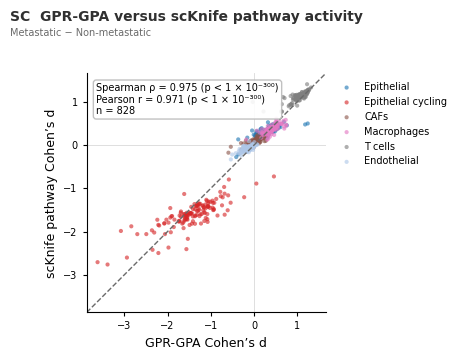

In [6]:
_render_panel_files('SC',['gpr_gpa_vs_scknife_effects.csv'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Supplementary Figure 6D — descriptive maps of the remaining cross-modal overlaps


,panel,file,rows,columns
0,SD,robust_activity_umap.csv.gz,69391,10


robust_activity_umap.csv.gz: first three rows


,cell_id,PatientID,Timepoint,Status,celltype,UMAP1,UMAP2,2_aminoethylphosphonate,Glutaryl_Carnitine,malonate
0,library4_sample3_AAACAAGCAAGCGAAGAGTAGGCT-1,P3,Surgery,Metastatic,Macrophages,14.044195,0.500485,0.879441,1.298581,0.671496
1,library4_sample3_AAACAAGCACCTCGACAGTAGGCT-1,P3,Surgery,Metastatic,Epithelial,0.319421,5.471742,0.080679,0.362660,0.085596
2,library4_sample3_AAACCAATCAATACAGAGTAGGCT-1,P3,Surgery,Metastatic,CAFs,2.368859,-2.954627,0.231183,0.165973,0.200659


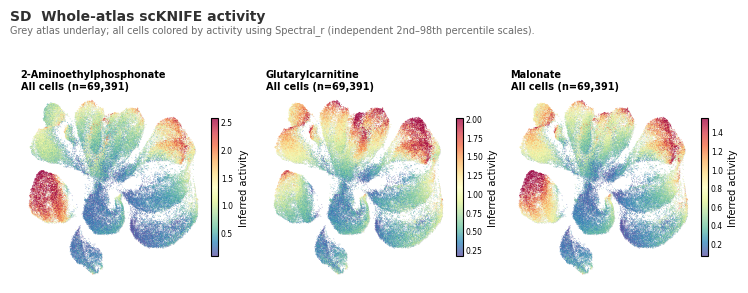

In [7]:
_render_panel_files('SD',['robust_activity_umap.csv.gz'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Supplementary Figure 6E — top paired biopsy-versus-surgery LC–MS metabolites


,panel,file,rows,columns
0,SE,selected_metabolite_statistics.csv,5,20
1,SE,selected_metabolite_values.csv,70,10


selected_metabolite_statistics.csv: first three rows


,panel,contrast,feature,display_name,selection_tier,putative_native_metabolite,inchikey,formula,polarity,mz,rt_seconds,log2_fold_change,t_score,nominal_p_value,joint_BH_FDR,native_score,precursor_ppm_error,rt_error_seconds,native_database,confidence_label
0,C,surgery_vs_biopsy,pos_174.9854_1689.69,Selenoamino acid metabolism\nm/z 174.9854 • RT...,Corrected pathway driver; pathway BH-FDR < 0.05,NaN,NaN,NaN,positive,174.985353,1689.685664,1.019093,4.377789,0.000746,0.029947,NaN,NaN,NaN,NaN,Unannotated LC-MS feature
1,C,surgery_vs_biopsy,pos_250.0920_262.79,Aspartate/asparagine metabolism\nm/z 250.0920 ...,Corrected pathway driver; pathway BH-FDR < 0.05,NaN,NaN,NaN,positive,250.091981,262.790738,1.497703,4.102346,0.001245,0.040790,NaN,NaN,NaN,NaN,Unannotated LC-MS feature
2,C,surgery_vs_biopsy,neg_246.9429_242.71,Glycolysis/gluconeogenesis\nm/z 246.9429 • RT ...,Corrected pathway driver; pathway BH-FDR < 0.05,NaN,NaN,NaN,negative,246.942913,242.707348,-2.865121,-4.297825,0.000867,0.031876,NaN,NaN,NaN,NaN,Unannotated LC-MS feature


selected_metabolite_values.csv: first three rows


,panel,contrast,feature,display_name,SpecimenID,log2_intensity,PatientID,PatientID_clean,Timepoint,Status
0,C,surgery_vs_biopsy,pos_174.9854_1689.69,Selenoamino acid metabolism\nm/z 174.9854 • RT...,CF_06685_1015172,20.706221,P1,CF_06685,Biopsy,Non-metastatic
1,C,surgery_vs_biopsy,pos_174.9854_1689.69,Selenoamino acid metabolism\nm/z 174.9854 • RT...,CF_06685_1016015,21.313748,P1,CF_06685,Surgery,Non-metastatic
2,C,surgery_vs_biopsy,pos_174.9854_1689.69,Selenoamino acid metabolism\nm/z 174.9854 • RT...,CF_16980_1016703,21.364657,P2,CF_16980,Biopsy,Metastatic


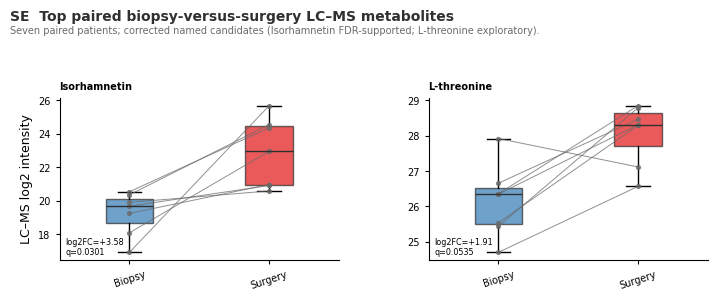

In [8]:
_render_panel_files('SE',['selected_metabolite_statistics.csv', 'selected_metabolite_values.csv'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Supplementary Figure 6F — MEIA versus scKnife: Surgery − Biopsy


,panel,file,rows,columns
0,SF,meia_vs_scknife_effects.csv,4272,7


meia_vs_scknife_effects.csv: first three rows


,comparison,contrast,cell_type,feature,feature_layer,x,y
0,MEIA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,scCellFie::(R)-3-Hydroxybutanoate synthesis,MEIA-Task,-0.333649,-0.150540
1,MEIA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,scCellFie::3'-Phospho-5'-adenylyl sulfate synt...,MEIA-Task,-0.024967,0.093251
2,MEIA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,scCellFie::AMP salvage from adenine,MEIA-Task,-0.495857,-0.594310


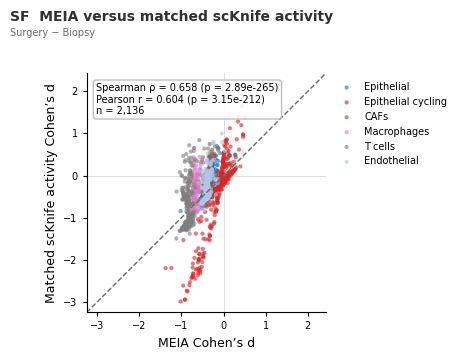

In [9]:
_render_panel_files('SF',['meia_vs_scknife_effects.csv'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Supplementary Figure 6G — MEIA versus scKnife: Metastatic − Non-metastatic


,panel,file,rows,columns
0,SG,meia_vs_scknife_effects.csv,4272,7


meia_vs_scknife_effects.csv: first three rows


,comparison,contrast,cell_type,feature,feature_layer,x,y
0,MEIA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,scCellFie::(R)-3-Hydroxybutanoate synthesis,MEIA-Task,-0.333649,-0.150540
1,MEIA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,scCellFie::3'-Phospho-5'-adenylyl sulfate synt...,MEIA-Task,-0.024967,0.093251
2,MEIA_vs_scKNIFE,surgery_vs_biopsy,Epithelial,scCellFie::AMP salvage from adenine,MEIA-Task,-0.495857,-0.594310


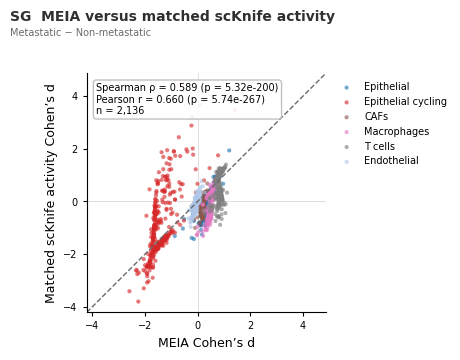

In [10]:
_render_panel_files('SG',['meia_vs_scknife_effects.csv'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Supplementary Figure 6H — MEIA-Pathway versus GPR-GPA: Surgery − Biopsy


,panel,file,rows,columns
0,SH,meia_pathway_vs_gpr_gpa_effects.csv,1656,7


meia_pathway_vs_gpr_gpa_effects.csv: first three rows


,comparison,contrast,cell_type,x,feature,y,feature_layer
0,MEIA_Pathway_vs_GPR_GPA,surgery_vs_biopsy,Epithelial,-0.248592,Glycolysis_Gluconeogenesis,-0.311755,Pathway
1,MEIA_Pathway_vs_GPR_GPA,surgery_vs_biopsy,Epithelial,-0.288093,Starch_and_sucrose_metabolism,-0.353714,Pathway
2,MEIA_Pathway_vs_GPR_GPA,surgery_vs_biopsy,Epithelial,-0.352948,Galactose_metabolism,-0.387398,Pathway


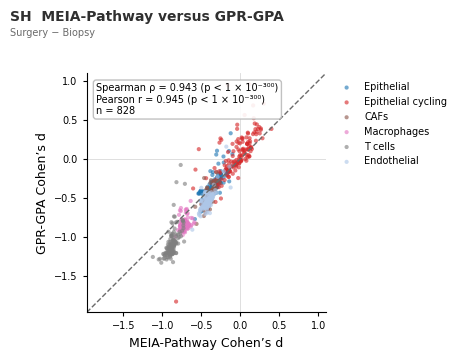

In [11]:
_render_panel_files('SH',['meia_pathway_vs_gpr_gpa_effects.csv'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Supplementary Figure 6I — MEIA-Pathway versus GPR-GPA: Metastatic − Non-metastatic


,panel,file,rows,columns
0,SI,meia_pathway_vs_gpr_gpa_effects.csv,1656,7


meia_pathway_vs_gpr_gpa_effects.csv: first three rows


,comparison,contrast,cell_type,x,feature,y,feature_layer
0,MEIA_Pathway_vs_GPR_GPA,surgery_vs_biopsy,Epithelial,-0.248592,Glycolysis_Gluconeogenesis,-0.311755,Pathway
1,MEIA_Pathway_vs_GPR_GPA,surgery_vs_biopsy,Epithelial,-0.288093,Starch_and_sucrose_metabolism,-0.353714,Pathway
2,MEIA_Pathway_vs_GPR_GPA,surgery_vs_biopsy,Epithelial,-0.352948,Galactose_metabolism,-0.387398,Pathway


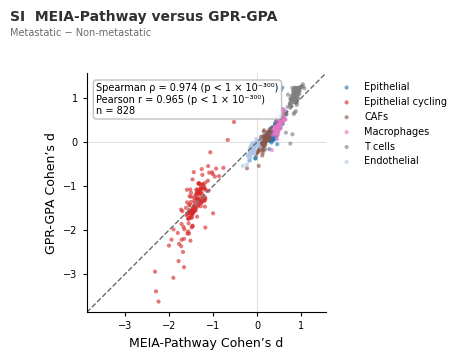

In [12]:
_render_panel_files('SI',['meia_pathway_vs_gpr_gpa_effects.csv'],SUPPLEMENTARY_DATA,'supplementary_panels')


## Compiled supplementary figure — rebuilt from live panel data

SA–SD are assembled from the DataFrames loaded in the individual cells above.

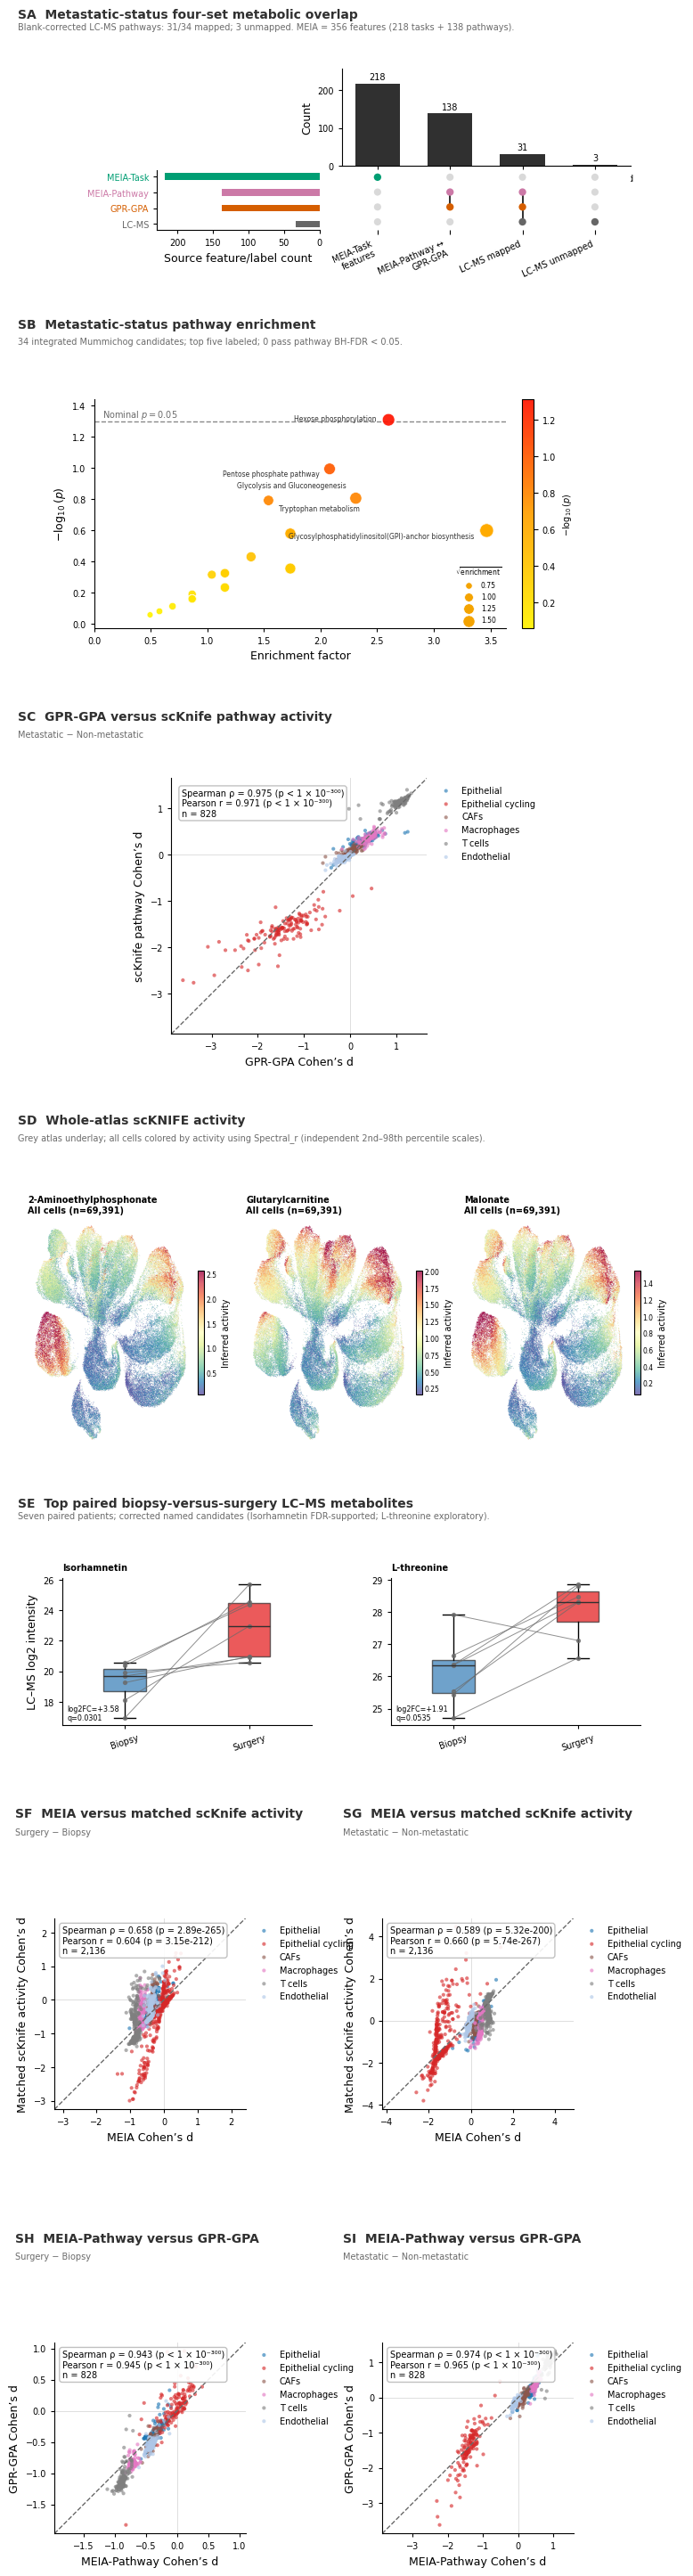

In [13]:
_supplementary_labels=("SA","SB","SC","SD","SE","SF","SG","SH","SI")
if set(SUPPLEMENTARY_DATA)!=set(_supplementary_labels):raise RuntimeError(f"Compiled supplementary figure requires SA–SI data; found {sorted(SUPPLEMENTARY_DATA)}")
_supplementary_data={}
for _label in _supplementary_labels:_supplementary_data.update(SUPPLEMENTARY_DATA[_label])
_supplementary_figure=make_figure6_supplementary(_supplementary_data)
for _suffix in ("png","pdf"):_supplementary_figure.savefig((ROOT/"outputs")/f"Figure_S6.{_suffix}",format=_suffix,dpi=OUTPUT_DPI,facecolor="white",bbox_inches="tight")
plt.figure(_supplementary_figure.number);plt.show();plt.close(_supplementary_figure)

## Statistical and annotation interpretation

- Main A summarizes mapping of the 22 blank-corrected Surgery-versus-Biopsy LC–MS pathways; B shows enrichment of those same 22 candidates.
- Main C compares GPR-GPA with independently calculated scKnife pathway effects for Surgery − Biopsy across all 138 Human-GEM pathways and six cell types (n = 828). The corresponding metastatic-status comparison is Supplementary SC.
- Main D uses Figure 5 graph seeds as a backbone, tests a glycoconjugate family once in integrated MEIA, and shows all-cell T-cell distributions with P1–P7 medians: activity decreases longitudinally and the biopsy metastatic elevation converges after surgery; GPR-GPA is contextual; E shows representative baseline-restoration trajectories; F shows the exploratory blank-corrected L-threonine cross-modal comparison.
- Supplementary SA–SB provide the parallel 34-pathway metastatic-status mapping and enrichment views. Supplementary SD contains the remaining descriptive cross-modal activity maps; SE contains the additional top paired LC–MS view.
- Supplementary SF–SG compare all MEIA tasks and pathways with matched scKnife activity; SH–SI compare MEIA-Pathway with GPR-GPA. Correlations pool feature × cell-type effects and report Spearman and Pearson statistics.
- MEIA, GPR-GPA, and scKnife scores are calculated independently despite sharing pathway annotations and expression inputs. Agreement therefore assesses score-construction concordance, not independent biological validation.
- MEIA-Task features are not forced into MEIA-Pathway versus GPR-GPA because GPR-GPA has no one-to-one task-level counterpart.
- Named LC–MS compounds remain putative MSI level-2 candidates pending authentic-standard confirmation.


## Literature context

Literature provenance used for candidate context is loaded and previewed directly in panels C and SC. It supports biological context only, not compound identity, direction, or causality.